# GNN en red de transporte
En este cuaderno interactivo, veremos la aplicación de GNN a un ejemplo real* de transporte (la red de metro y tren rápido de Montreal)<br>
Las coordenadas y conexiones de las estaciones fueron obtenidos usando la api de la librería *overpy* para importar los datos geográficos (versión libre similar a google-maps)<br> Los datos son cargados desde un archivo que contiene el grafo en formato json compatible con Networkx ()
<br>


In [1]:
! pip install overpy

### Ejemplo


## Librerías para grafos y mapas
*networkx* permite trabajar con grafos, incluyendo datos para cada nodo y arista. <br>
*geopandas* permite guardar bases de datos que incluyen campos geográficos <br>
*overpy* importa lugares de interés <br>
*folium* permite dibujar el mapa


In [106]:
#!pip install overpy geopandas folium networkx


[Montreal Transport map](./montreal_transport_full.html)


Los datos fueron cargados con Overpy y almacenados en un archivo de formato json. El Grafo leèido contiene atributos de nodos y aristas

In [3]:

import json
import networkx as nx
from networkx.readwrite import json_graph
import matplotlib.pyplot as plt


# 1. Cargar los datos desde el archivo JSON
with open("G_metro.json", "r", encoding="utf-8") as archivo:
    datos_json = json.load(archivo)

# 2. Reconstruir el grafo de NetworkX
G = json_graph.node_link_graph(datos_json)

# print(f"Nodos: {G.nodes()}")
# print(f"Enlaces: {G.edges()}")



C:\Users\David\anaconda3\Lib\site-packages\networkx\readwrite\json_graph\node_link.py:290: FutureWarning: 
The default value will be changed to `edges="edges" in NetworkX 3.6.

To make this warning go away, explicitly set the edges kwarg, e.g.:

  nx.node_link_graph(data, edges="links") to preserve current behavior, or
  nx.node_link_graph(data, edges="edges") for forward compatibility.
  warnings.warn(


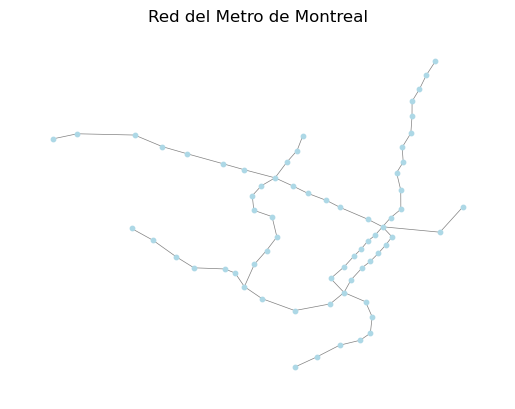

In [107]:

posicion = nx.get_node_attributes(G,'pos')
etiquetas = nx.get_node_attributes(G,'name')


#  Dibujar los componentes del grafo
nx.draw_networkx_nodes(G, posicion, node_color="lightblue", node_size=10)
nx.draw_networkx_edges(G, posicion, edge_color="gray", width=0.5)
#nx.draw_networkx_labels(G, posicion, font_size=3, font_family="sans-serif",labels = etiquetas )

#  Mostrar la ventana con el gráfico
plt.title("Red del Metro de Montreal")
plt.axis("off")  # Oculta los ejes numéricos x/y
plt.show()

In [5]:

import pandas as pd
import requests

# Cargar los atributos de cada nodo



La información de un nodo se carga dentro de una tabla de datos (dataframe). 

In [6]:
nodos_grafo=pd.DataFrame.from_dict(dict(G.nodes(data=True)), orient='index')
nodos_grafo

,name,operator,pos
6600856333,Berri-UQAM,Société de transport de Montréal,"[-73.5610756, 45.5151125]"
213329687,Atwater,Société de transport de Montréal,"[-73.5863126, 45.4896787]"
7052605729,Côte-Vertu,Société de transport de Montréal,"[-73.6832845, 45.5142942]"
7052605730,Du Collège,Société de transport de Montréal,"[-73.6728291, 45.5084616]"
7052605731,De La Savane,Société de transport de Montréal,"[-73.6615981, 45.5003824]"
...,...,...,...
6615202529,De l'Église,Société de transport de Montréal,"[-73.5670231, 45.4627596]"
6615202530,Charlevoix,Société de transport de Montréal,"[-73.5693705, 45.4782496]"
6615202531,Préfontaine,Société de transport de Montréal,"[-73.5542369, 45.5417253]"
6607411941,Villa-Maria,Société de transport de Montréal,"[-73.6197555, 45.4797551]"


# Combinar con otros atributos
Aumentar otros datos datos relacionados a cada nodo (por ejemplo, afluencia de las estaciones). Al ser de otra fuente, serèa necesario jugar con *pandas*

In [7]:
!pip install cloudscraper
!pip install unidecode

import cloudscraper
from bs4 import BeautifulSoup
import pandas as pd
from unidecode import unidecode

# Inicializar el scraper que emula un navegador real frente a Cloudflare
scraper = cloudscraper.create_scraper()

url = "https://www.railfans.ca/metro/stations"

try:
    response = scraper.get(url)
    if response.status_code == 200:
        soup = BeautifulSoup(response.text, 'html.parser')
        
        # Localizar la tabla en el HTML
        tabla = soup.find('table')
        
        if tabla:
            # pandas puede leer directamente estructuras de tablas HTML mapeadas por BeautifulSoup
            df_lista = pd.read_html(str(tabla))
            df = df_lista[0]
            
            # Guardar los datos en un archivo CSV limpio
            df.to_csv("railfans_ridership.csv", index=False)
            print("¡Tabla guardada exitosamente como 'railfans_ridership.csv'!")
            # print(df.head())
        else:
            print("No se encontró ninguna etiqueta <table> en esta URL.")
    else:
        print(f"Error de acceso persistente. Código de estado: {response.status_code}")
except Exception as e:
    print(f"Error durante la ejecución del script: {e}")
df.columns = df.iloc[0]  # Define la fila 0 como los nombres de las columnas
df = df[1:]             # Conserva los datos desde la fila 1 en adelante
df.Station =  df.Station.apply(unidecode).str.upper() # Reinicia los índices para que empiecen en 0

df["Station"] = df.Station.replace(
    {'IBERVILLE':"D'IBERVILLE",
 'LONGUEUIL- UNIVERSITE-DE-SHERBROOKE': 'LONGUEUIL-UNIVERSITE-DE-SHERBROOKE',
 'PIE-IX': 'PIE IX',
 "PLACE-D'ARMES": "PLACE D'ARMES",
 'SQUARE VICTORIA-OACI' : 'SQUARE-VICTORIA-OACI'})

df = df.set_index('Station')

# 2. Eliminamos la última fila (los Totales)
df = df.iloc[:-1]       # Corta el DataFrame justo antes de la última fila

# Mostrar el resultado limpio


¡Tabla guardada exitosamente como 'railfans_ridership.csv'!


C:\Users\David\AppData\Local\Temp\ipykernel_4896\1188441545.py:24: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  df_lista = pd.read_html(str(tabla))
C:\Users\David\AppData\Local\Temp\ipykernel_4896\1188441545.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.Station =  df.Station.apply(unidecode).str.upper() # Reinicia los índices para que empiecen en 0
C:\Users\David\AppData\Local\Temp\ipykernel_4896\1188441545.py:41: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.

In [8]:
display(df)

,Total Entries in 2024,Weekday Average 2024,Weekend Average 2024
Station,,,
ACADIE,1239419,3919,2045
ANGRIGNON,4291952,13080,8318
ASSOMPTION,1335163,4197,2264
ATWATER,6175400,19537,10161
BEAUBIEN,3264023,9696,6957
...,...,...,...
UNIVERSITE-DE-MONTREAL,2818907,9840,2316
VENDOME,6031289,19550,8743
VERDUN,1542247,4685,3026


In [9]:
nodos_grafo

,name,operator,pos
6600856333,Berri-UQAM,Société de transport de Montréal,"[-73.5610756, 45.5151125]"
213329687,Atwater,Société de transport de Montréal,"[-73.5863126, 45.4896787]"
7052605729,Côte-Vertu,Société de transport de Montréal,"[-73.6832845, 45.5142942]"
7052605730,Du Collège,Société de transport de Montréal,"[-73.6728291, 45.5084616]"
7052605731,De La Savane,Société de transport de Montréal,"[-73.6615981, 45.5003824]"
...,...,...,...
6615202529,De l'Église,Société de transport de Montréal,"[-73.5670231, 45.4627596]"
6615202530,Charlevoix,Société de transport de Montréal,"[-73.5693705, 45.4782496]"
6615202531,Préfontaine,Société de transport de Montréal,"[-73.5542369, 45.5417253]"
6607411941,Villa-Maria,Société de transport de Montréal,"[-73.6197555, 45.4797551]"


In [10]:
nodos_grafo["name"] = nodos_grafo.name.apply(unidecode).str.upper()
nodos_grafo = nodos_grafo.set_index('name')

In [11]:
nodos_grafo.operator

name
BERRI-UQAM      Société de transport de Montréal
ATWATER         Société de transport de Montréal
COTE-VERTU      Société de transport de Montréal
DU COLLEGE      Société de transport de Montréal
DE LA SAVANE    Société de transport de Montréal
                              ...               
DE L'EGLISE     Société de transport de Montréal
CHARLEVOIX      Société de transport de Montréal
PREFONTAINE     Société de transport de Montréal
VILLA-MARIA     Société de transport de Montréal
SNOWDON         Société de transport de Montréal
Name: operator, Length: 68, dtype: object

# Combinar los atributos en una sola tabla de datos 

Nota: Unidecode se usa para poder unificar las cadenas que contienen acentos con las que no. En algunos casos, una verificación manual tambièen fue necesaria.

In [12]:
from unidecode import unidecode

print([ nombre for nombre in nodos_grafo.index.to_list() if nombre not in df.index.to_list()])
[ unidecode(nombre) for nombre in df.index.to_list() if nombre not in nodos_grafo.index.to_list()]

[]


[]

In [13]:
df_full = df.join(nodos_grafo) 
df_full

,Total Entries in 2024,Weekday Average 2024,Weekend Average 2024,operator,pos
Station,,,,,
ACADIE,1239419,3919,2045,Société de transport de Montréal,"[-73.6237511, 45.523225]"
ANGRIGNON,4291952,13080,8318,Société de transport de Montréal,"[-73.6036506, 45.4461825]"
ASSOMPTION,1335163,4197,2264,Société de transport de Montréal,"[-73.5467318, 45.5693911]"
ATWATER,6175400,19537,10161,Société de transport de Montréal,"[-73.5863126, 45.4896787]"
BEAUBIEN,3264023,9696,6957,Société de transport de Montréal,"[-73.6046246, 45.5351198]"
...,...,...,...,...,...
UNIVERSITE-DE-MONTREAL,2818907,9840,2316,Société de transport de Montréal,"[-73.617581, 45.503439]"
VENDOME,6031289,19550,8743,Société de transport de Montréal,"[-73.6038307, 45.4738941]"
VERDUN,1542247,4685,3026,Société de transport de Montréal,"[-73.5720103, 45.4592869]"


# El Problema a analizar
Las estaciones fueron categorizadas (un poco arbitrariamente) en tres tipos:
* Terminales/transferencia: Estaciones en las que se puede hacer una conexièon dentro del sistema o con otros modos de transporte.
* Turísticas: Estaciones cercanas a puntos de interèes de la Ciudad
* Residenciales: El resto de estaciones

Se intentará clasificar las estaciones a partir de los datos disponibles de afluencia, y ubicación de cada estación. 

In [84]:
hub={"Berri-UQAM","Jean-Talon","Lionel-Groulx","Snowdon","Vendôme","Longueuil-Université-de-Sherbrooke","Longueuil–Université-de-Sherbrooke","Montmorency","Henri-Bourassa","Côte-Vertu","Honoré-Beaugrand","Angrignon","Saint-Michel","Jarry","Parc","Bonaventure"}
touristic={"Jean-Drapeau","Champ-de-Mars","Place-d'Armes","Côte-des-neiges","Place-des-Arts","Viau","McGill","Peel","Square-Victoria-OACI","Saint-Laurent","Atwater","Guy-Concordia"}
hub = [unidecode(s).upper() for s in hub]
touristic = [unidecode(s).upper() for s in touristic] 
print (hub, touristic)
def label(s): return "terminal/hub" if s in hub else ("touristic" if unidecode(s).upper() in touristic else "residential")
def norm(s):
    s=unicodedata.normalize("NFKD",str(s)); s="".join(c for c in s if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]","",s.lower().replace("–","-").replace("—","-"))
df_full["label"]=df_full.index.map(label)
df_full["label"]

['LONGUEUIL-UNIVERSITE-DE-SHERBROOKE', 'VENDOME', 'HENRI-BOURASSA', 'MONTMORENCY', 'SNOWDON', 'COTE-VERTU', 'PARC', 'LONGUEUIL-UNIVERSITE-DE-SHERBROOKE', 'LIONEL-GROULX', 'BERRI-UQAM', 'BONAVENTURE', 'ANGRIGNON', 'HONORE-BEAUGRAND', 'JARRY', 'JEAN-TALON', 'SAINT-MICHEL'] ['MCGILL', 'JEAN-DRAPEAU', 'PEEL', 'PLACE-DES-ARTS', 'SQUARE-VICTORIA-OACI', "PLACE-D'ARMES", 'CHAMP-DE-MARS', 'SAINT-LAURENT', 'ATWATER', 'VIAU', 'COTE-DES-NEIGES', 'GUY-CONCORDIA']


Station
ACADIE                     residential
ANGRIGNON                 terminal/hub
ASSOMPTION                 residential
ATWATER                      touristic
BEAUBIEN                   residential
                              ...     
UNIVERSITE-DE-MONTREAL     residential
VENDOME                   terminal/hub
VERDUN                     residential
VIAU                         touristic
VILLA-MARIA                residential
Name: label, Length: 68, dtype: object

In [85]:
for tag in ["Weekday Average 2024","Weekend Average 2024","Total Entries in 2024"]:
    df_full[tag] = pd.to_numeric(df_full[tag]).astype('Int64')


In [86]:
df_full.dtypes

Total Entries in 2024      Int64
Weekday Average 2024       Int64
Weekend Average 2024       Int64
operator                  object
pos                       object
label                     object
degree                     int64
target                     int64
lon                      float64
lat                      float64
dtype: object

Las aristas también pueden contener información (en este caso, la distancia entre estaciones vecinas)

In [87]:
pd.DataFrame.from_dict(dict(G.edges),orient = 'index')

weight  \
6600856333 6600874117  2.197876   
           7052605742  0.675600   
           7052605741  0.658085   
           7052992090  0.579630   
           7052992091  0.552997   
...                         ...   
7052471489 7052471490  0.639271   
7052471490 7052471491  0.801850   
7052471492 7052471493  0.842035   
7052949183 7052949184  0.813125   
6607411941 6607411942  0.939111   

                                                                    line  \
6600856333 6600874117  Ligne jaune vers Longueuil–Université-de-Sherb...   
           7052605742                      Ligne orange vers Montmorency   
           7052605741                      Ligne orange vers Montmorency   
           7052992090                  Ligne verte vers Honoré-Beaugrand   
           7052992091                  Ligne verte vers Honoré-Beaugrand   
...                                                                  ...   
7052471489 7052471490                           Ligne bleue vers Snowdon   
7052471490 7052471491                           Ligne bleue vers Snowdon   
7052471492 7052471493                           Ligne bleue vers Snowdon   
7052949183 7052949184                  Ligne verte vers Honoré-Beaugrand   
6607411941 6607411942                      Ligne orange vers Montmorency   

                                                              route_type  
6600856333 6600874117   {'85': 'subway', '86': 'subway', '87': 'subway'}  
           7052605742  {'27': 'subway', '28': 'subway', '29': 'subway...  
           7052605741  {'27': 'subway', '28': 'subway', '29': 'subway...  
           7052992090  {'0': 'subway', '1': 'subway', '2': 'subway', ...  
           7052992091  {'0': 'subway', '1': 'subway', '2': 'subway', ...  
...                                                                  ...  
7052471489 7052471490  {'73': 'subway', '74': 'subway', '75': 'subway...  
7052471490 7052471491  {'73': 'subway', '74': 'subway', '75': 'subway...  
7052471492 7052471493  {'73': 'subway', '74': 'subway', '75': 'subway...  
7052949183 7052949184  {'0': 'subway', '1': 'subway', '2': 'subway', ...  
6607411941 6607411942  {'27': 'subway', '28': 'subway', '29': 'subway...  

[69 rows x 3 columns]

In [88]:
{code:etiqueta for code,etiqueta in etiquetas.items() if etiqueta in hub}

{}

blue [7052605730, 7052605731, 7052605732, 7052605733, 7052605734, 7052605736, 7052605740, 7052605742, 7052605737, 7052605744, 7052605745, 7052605746, 5360360498, 7052605749, 7052605751, 7052605748, 7052992085, 7052992086, 7052992087, 7052992088, 7052992089, 7052992090, 7052992097, 7052992098, 7052992099, 7041520765, 1765620875, 7758614182, 7052605743, 7052471486, 7052471487, 7052471489, 7052471491, 7052471492, 7052471493, 7052949183, 7052949184, 6615202528, 6615202529, 6615202530, 6615202531, 6607411941]
orange [213329687, 6600830244, 7052605739, 7052605741, 7052992091, 7052992092, 7052992094, 7052992095, 6831524451, 6600874117, 6615202527]
green [6600856333, 7052605729, 6600830243, 7052605738, 7052605735, 7052605747, 7052605750, 7052992100, 7041520766, 7164242333, 7757580977, 7052471485, 7052471488, 7052471490, 6607411942]


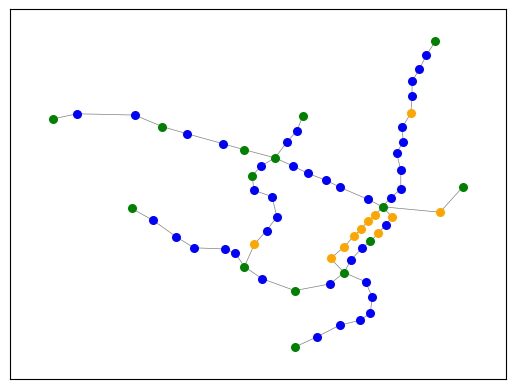

In [101]:
palette={"residential":"blue","touristic":"orange","terminal/hub":"green"}

posicion = nx.get_node_attributes(G,'pos')
etiquetas = nx.get_node_attributes(G,'name')

#  Dibujar los componentes del grafo
for tipo,color in palette.items():
    lista = [code for code,etiqueta in etiquetas.items() if label(unidecode(etiqueta).upper()) == tipo]
    print (color,lista)

    nx.draw_networkx_nodes(G,  posicion, node_color= color, node_size=30, nodelist = lista)
nx.draw_networkx_edges(G, posicion, edge_color="gray", width=0.5)


# Modelo de ML (normal)

Para tener una base para la comparación, usaremos un modelo usual de ML (Capas lineales completas).
Usaremos como predictores: Afluencia anual, Afluencia media entre semana, afluencia media del fin de semana, grado, latitud y longitud de cada estacièon

In [91]:
df_full[["lon","lat"]] = pd.DataFrame(df_full['pos'].tolist(), index=df_full.index)

In [92]:
grados = {unidecode(etiquetas[code]).upper():dict(G.degree())[code] for code in etiquetas }
print (grados)
df_full["degree"]=df_full.index.map(grados)


{'BERRI-UQAM': 5, 'ATWATER': 2, 'COTE-VERTU': 1, 'DU COLLEGE': 2, 'DE LA SAVANE': 2, 'NAMUR': 2, 'PLAMONDON': 2, 'LONGUEUIL-UNIVERSITE-DE-SHERBROOKE': 1, 'COTE-SAINTE-CATHERINE': 2, 'PLACE SAINT-HENRI': 2, 'COTE-DES-NEIGES': 2, 'BONAVENTURE': 2, 'SQUARE-VICTORIA-OACI': 2, 'VENDOME': 2, "PLACE D'ARMES": 2, 'CHAMP-DE-MARS': 2, 'SHERBROOKE': 2, 'GEORGES-VANIER': 2, 'LAURIER': 2, 'ROSEMONT': 2, 'BEAUBIEN': 2, 'JARRY': 2, "LUCIEN-L'ALLIER": 2, 'SAUVE': 2, 'HENRI-BOURASSA': 2, 'DE LA CONCORDE': 2, 'CREMAZIE': 2, 'ASSOMPTION': 2, 'PIE IX': 2, 'JOLIETTE': 2, 'FRONTENAC': 2, 'PAPINEAU': 2, 'BEAUDRY': 2, 'SAINT-LAURENT': 2, 'PLACE-DES-ARTS': 2, 'PEEL': 2, 'GUY-CONCORDIA': 2, 'LASALLE': 2, 'VERDUN': 2, 'JOLICOEUR': 2, 'MCGILL': 2, 'ANGRIGNON': 1, 'CADILLAC': 2, 'HONORE-BEAUGRAND': 1, 'JEAN-DRAPEAU': 2, 'OUTREMONT': 2, 'LIONEL-GROULX': 4, 'CARTIER': 2, 'MONTMORENCY': 1, 'MONT-ROYAL': 2, 'SAINT-MICHEL': 1, "D'IBERVILLE": 2, 'FABRE': 2, 'JEAN-TALON': 4, 'DE CASTELNAU': 2, 'PARC': 2, 'ACADIE': 2, 'ED

In [93]:
import numpy as np

In [94]:
df_full.columns.to_list()

['Total Entries in 2024',
 'Weekday Average 2024',
 'Weekend Average 2024',
 'operator',
 'pos',
 'label',
 'degree',
 'target',
 'lon',
 'lat']

In [196]:
class_names=["residential","touristic","terminal/hub"]; to_id={s:i for i,s in enumerate(class_names)}
df_full["target"]=df_full.label.map(to_id).astype(int)
features =['Total Entries in 2024','Weekday Average 2024',
 'Weekend Average 2024', 'degree',"lat","lon"]
features_2 = ['Weekday Average 2024',
 'Weekend Average 2024', 'degree',"lat","lon"]


X=df_full[features].to_numpy(np.float32); y=df_full.target.to_numpy(np.int64)
X = df_full[features_2].to_numpy(np.float32); y=df_full.target.to_numpy(np.int64)

print("Matched stations:",len(df),"of ",len(G))
print(df_full.label.value_counts())
display(df_full[features+["label"]].head(68))


Matched stations: 68 of  68
label
residential     42
terminal/hub    15
touristic       11
Name: count, dtype: int64


,Total Entries in 2024,Weekday Average 2024,Weekend Average 2024,degree,lat,lon,label
Station,,,,,,,
ACADIE,1239419,3919,2045,2,45.523225,-73.623751,residential
ANGRIGNON,4291952,13080,8318,1,45.446182,-73.603651,terminal/hub
ASSOMPTION,1335163,4197,2264,2,45.569391,-73.546732,residential
ATWATER,6175400,19537,10161,2,45.489679,-73.586313,touristic
BEAUBIEN,3264023,9696,6957,2,45.535120,-73.604625,residential
...,...,...,...,...,...,...,...
UNIVERSITE-DE-MONTREAL,2818907,9840,2316,2,45.503439,-73.617581,residential
VENDOME,6031289,19550,8743,2,45.473894,-73.603831,terminal/hub
VERDUN,1542247,4685,3026,2,45.459287,-73.572010,residential


In [190]:
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier#, LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from torch_geometric.nn import GCNConv, NNConv

SEED=42
np.random.seed(SEED); torch.manual_seed(SEED)


MLP CV accuracy: 0.662
              precision    recall  f1-score   support

 residential       0.78      0.83      0.80        42
   touristic       0.31      0.36      0.33        11
terminal/hub       0.60      0.40      0.48        15

    accuracy                           0.66        68
   macro avg       0.56      0.53      0.54        68
weighted avg       0.66      0.66      0.66        68



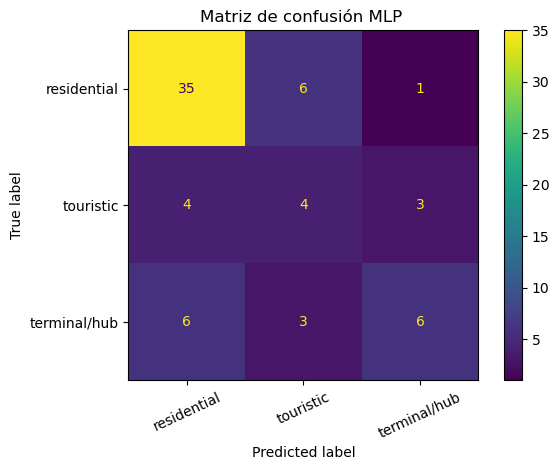

CPU times: total: 7.98 s
Wall time: 8.62 s


In [197]:
%%time
min_count=int(pd.Series(y).value_counts().min())
n_splits=min(5,min_count)
if n_splits<2: raise ValueError("Need at least two stations in each class for stratified cross-validation.")
cv=StratifiedKFold(n_splits=n_splits,shuffle=True,random_state=42)
mlp=make_pipeline(StandardScaler(),MLPClassifier(hidden_layer_sizes=(16,8,8),max_iter=2500,alpha=.01,random_state=42))
mlp_pred=cross_val_predict(mlp,X,y,cv=cv)
print("MLP CV accuracy:",round(accuracy_score(y,mlp_pred),3))
print(classification_report(y,mlp_pred,labels=range(3),target_names=class_names,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y,mlp_pred,labels=range(3),display_labels=class_names,xticks_rotation=25)
plt.title("Matriz de confusión MLP "); plt.tight_layout(); plt.show()


In [198]:
print(mlp_pred,y)

[0 1 0 2 2 1 2 1 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 1 0 0 0 0 0
 2 0 0 2 0 1 2 0 0 1 0 1 0 0 1 1 1 0 0 0 0 2 0 1 0 2 0 2 0 0 0] [0 2 0 1 0 0 2 2 0 0 1 0 1 0 2 0 0 0 0 0 0 0 0 0 0 1 2 2 0 2 1 2 0 0 0 0 0
 2 2 0 1 0 0 2 0 0 0 2 1 0 0 0 1 0 0 0 0 1 2 0 0 2 1 0 2 0 1 0]


In [199]:
result_df_MLP = pd.DataFrame(
    data={"mlp_pred": mlp_pred, "y": y},
    index=df_full.index
)
result_df_MLP

,mlp_pred,y
Station,,
ACADIE,0,0
ANGRIGNON,1,2
ASSOMPTION,0,0
ATWATER,2,1
BEAUBIEN,2,0
...,...,...
UNIVERSITE-DE-MONTREAL,0,0
VENDOME,2,2
VERDUN,0,0


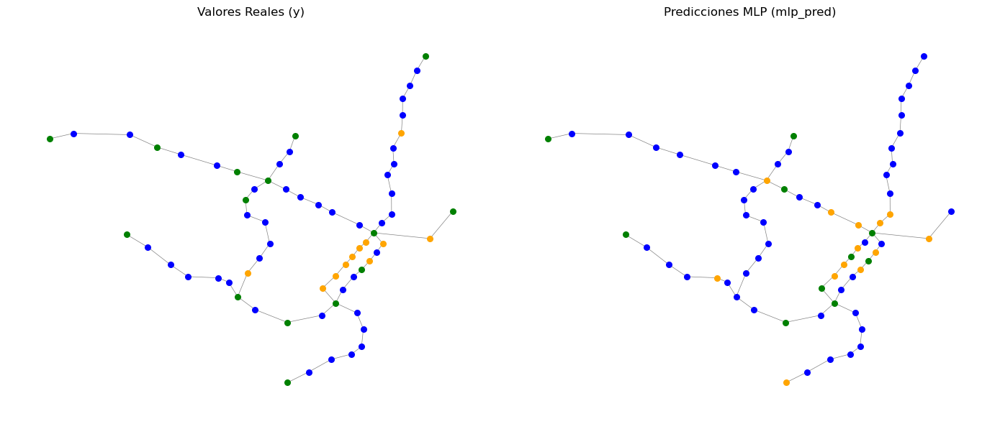

In [200]:
palette={"residential":"blue","touristic":"orange","terminal/hub":"green"}
palette_pred={0:"blue",1:"orange",2:"green"}

posicion = nx.get_node_attributes(G,'pos')
etiquetas = nx.get_node_attributes(G,'name')


# 1. Configurar la cuadrícula: 1 fila, 2 columnas
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))

# ==================== PRIMER SUBPLOT (ax1) ====================
ax1.set_title("Valores Reales (y)")

# Dibujar nodos en ax1
for tipo, color in palette_pred.items():
    lista = [code for code, etiqueta in etiquetas.items() if result_df_MLP["y"][unidecode(etiqueta).upper()] == tipo]
    
    nx.draw_networkx_nodes(G, posicion, node_color=color, node_size=30, nodelist=lista, ax=ax1)

# Dibujar aristas en ax1
nx.draw_networkx_edges(G, posicion, edge_color="gray", width=0.5, ax=ax1)
ax1.axis('off')  # Oculta los ejes numéricos para una mejor estética del grafo


# ==================== SEGUNDO SUBPLOT (ax2) ====================
ax2.set_title("Predicciones MLP (mlp_pred)")

# Dibujar nodos en ax2
for tipo, color in palette_pred.items():
    lista = [code for code, etiqueta in etiquetas.items() if result_df_MLP["mlp_pred"][unidecode(etiqueta).upper()] == tipo]
    
    nx.draw_networkx_nodes(G, posicion, node_color=color, node_size=30, nodelist=lista, ax=ax2)

# Dibujar aristas en ax2
nx.draw_networkx_edges(G, posicion, edge_color="gray", width=0.5, ax=ax2)
ax2.axis('off')  # Oculta los ejes numéricos en el segundo grafo


# 2. Mostrar y ajustar el diseño
plt.tight_layout()
plt.show()

# GCN

GCN CV accuracy: 0.412
              precision    recall  f1-score   support

 residential       0.62      0.55      0.58        42
   touristic       0.14      0.18      0.16        11
terminal/hub       0.18      0.20      0.19        15

    accuracy                           0.41        68
   macro avg       0.31      0.31      0.31        68
weighted avg       0.45      0.41      0.43        68



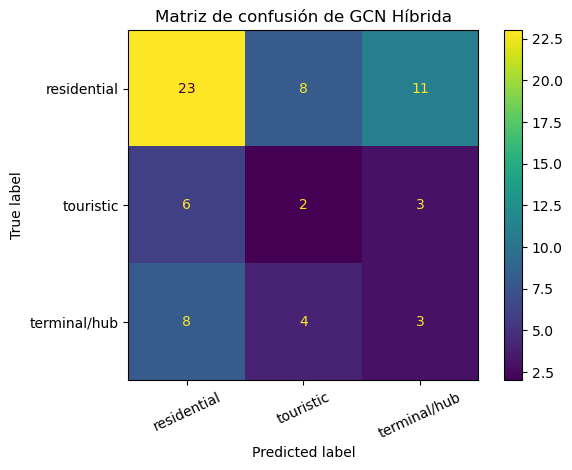

CPU times: total: 17.1 s
Wall time: 10.1 s


In [204]:
%%time
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Preparación de índices y Grafo (Asegurar mapeo correcto)
node_names = G.nodes #df_full.index.tolist()
idx = {s: i for i, s in enumerate(node_names)}
SG = G.subgraph(node_names)

pairs = []
for u, v in SG.edges():
    if u in idx and v in idx: # Validación de seguridad
        i, j = idx[u], idx[v]
        pairs.extend([[i, j], [j, i]])
#for u,i in idx.items():
#    pairs.extend([[i,i]])

edge_index = torch.tensor(pairs, dtype=torch.long).t().contiguous()
yt = torch.tensor(y, dtype=torch.long)

# 2. Definición del Modelo GCN
class GCNCombinada(nn.Module):
    def __init__(self):
        super().__init__()
        # Capas de convolución 
        self.c1 = GCNConv(5, 16) 
        self.c2 = GCNConv(16, 16) 
        #self.c3 = GCNConv(16, 16) 
        
        # Clasificación densa individual (Nodo a Nodo)
        self.fc1 = nn.Linear(16, 8)
        self.fc2 = nn.Linear(8, 3) # Salida para las 3 clases
        
    def forward(self, x, ei):
        # Paso 1: Convolución de grafos (agregación de vecinos)
        x = F.relu(self.c1(x, ei))
        #x = F.dropout(x, p=0.25, training=self.training)
        x = F.relu(self.c2(x, ei))
        #x = F.dropout(x, p=0.25, training=self.training)
        #x = F.relu(self.c3(x, ei))
        #x = F.dropout(x, p=0.25, training=self.training)
        
        # Paso 2: Capas densas estándar
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# 3. Función de ajuste transductiva
def fit_gcn(train, test, epochs=250):
    scaler = StandardScaler().fit(X[train])
    xt = torch.tensor(scaler.transform(X), dtype=torch.float32)
    
    model = GCNCombinada()
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    tr = torch.tensor(train, dtype=torch.long)
    
    for _ in range(epochs):
        model.train()
        opt.zero_grad()
        
        out = model(xt, edge_index)
        loss = F.cross_entropy(out[tr], yt[tr]) # Entrenamiento semisupervisado
        loss.backward()
        opt.step()
        
    model.eval()
    with torch.no_grad():
        pred = model(xt, edge_index).argmax(1)
        
    return pred[test].numpy()

# 4. Ejecución de la Validación Cruzada con StratifiedKFold
gcn_pred = np.zeros_like(y)
for tr, te in cv.split(X, y):
    gcn_pred[te] = fit_gcn(tr, te)

# 5. Reporte de Métricas Finales
print("GCN CV accuracy:", round(accuracy_score(y, gcn_pred), 3))
print(classification_report(y, gcn_pred, labels=range(3), target_names=class_names, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y, gcn_pred, labels=range(3), display_labels=class_names, xticks_rotation=25)
plt.title("Matriz de confusión de GCN Híbrida")
plt.tight_layout()
plt.show()



In [205]:
result_df_GCN = pd.DataFrame(
    data={"gcn_pred": gcn_pred, "y": y},
    index=df_full.index
)
result_df_GCN

,gcn_pred,y
Station,,
ACADIE,0,0
ANGRIGNON,0,2
ASSOMPTION,1,0
ATWATER,0,1
BEAUBIEN,0,0
...,...,...
UNIVERSITE-DE-MONTREAL,2,0
VENDOME,2,2
VERDUN,1,0


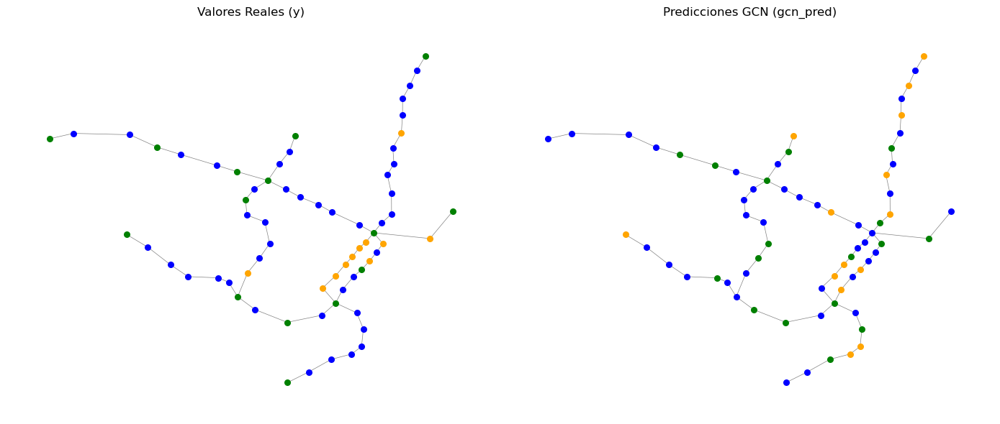

In [206]:
palette={"residential":"blue","touristic":"orange","terminal/hub":"green"}
palette_pred={0:"blue",1:"orange",2:"green"}

posicion = nx.get_node_attributes(G,'pos')
etiquetas = nx.get_node_attributes(G,'name')


# 1. Configurar la cuadrícula: 1 fila, 2 columnas
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))

# ==================== PRIMER SUBPLOT (ax1) ====================
ax1.set_title("Valores Reales (y)")

# Dibujar nodos en ax1
for tipo, color in palette_pred.items():
    lista = [code for code, etiqueta in etiquetas.items() if result_df_GCN["y"][unidecode(etiqueta).upper()] == tipo]
    
    nx.draw_networkx_nodes(G, posicion, node_color=color, node_size=30, nodelist=lista, ax=ax1)

# Dibujar aristas en ax1
nx.draw_networkx_edges(G, posicion, edge_color="gray", width=0.5, ax=ax1)
ax1.axis('off')  # Oculta los ejes numéricos para una mejor estética del grafo


# ==================== SEGUNDO SUBPLOT (ax2) ====================
ax2.set_title("Predicciones GCN (gcn_pred)")

# Dibujar nodos en ax2
for tipo, color in palette_pred.items():
    lista = [code for code, etiqueta in etiquetas.items() if result_df_GCN["gcn_pred"][unidecode(etiqueta).upper()] == tipo]
    
    nx.draw_networkx_nodes(G, posicion, node_color=color, node_size=30, nodelist=lista, ax=ax2)

# Dibujar aristas en ax2
nx.draw_networkx_edges(G, posicion, edge_color="gray", width=0.5, ax=ax2)
ax2.axis('off')  # Oculta los ejes numéricos en el segundo grafo


# 2. Mostrar y ajustar el diseño
plt.tight_layout()
plt.show()

GCN CV accuracy: 0.5
              precision    recall  f1-score   support

 residential       0.60      0.69      0.64        42
   touristic       0.25      0.27      0.26        11
terminal/hub       0.25      0.13      0.17        15

    accuracy                           0.50        68
   macro avg       0.37      0.37      0.36        68
weighted avg       0.47      0.50      0.48        68



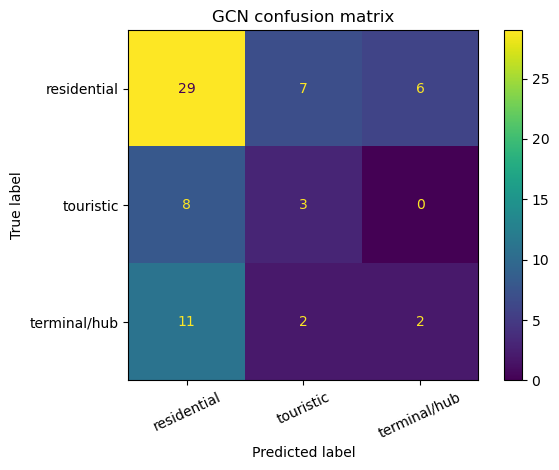

In [105]:
from sklearn.model_selection import StratifiedKFold
node_names=G.nodes; idx={s:i for i,s in enumerate(node_names)}
SG=G.subgraph(node_names)
pairs=[]
for u,v in SG.edges():
    i,j=idx[u],idx[v]; pairs.extend([[i,j],[j,i]])
edge_index=torch.tensor(pairs,dtype=torch.long).t().contiguous()
yt=torch.tensor(y,dtype=torch.long)

class GCN(nn.Module):
    def __init__(self):
        super().__init__(); self.c1=GCNConv(6,16); self.c2=GCNConv(16,3)
    def forward(self,x,ei):
        x=F.relu(self.c1(x,ei)); x=F.dropout(x,p=.25,training=self.training)
        return self.c2(x,ei)

def fit_gcn(train,test,epochs=250):
    scaler=StandardScaler().fit(X[train]); xt=torch.tensor(scaler.transform(X),dtype=torch.float32)
    model=GCN(); opt=torch.optim.Adam(model.parameters(),lr=.01,weight_decay=5e-4)
    tr=torch.tensor(train,dtype=torch.long); te=torch.tensor(test,dtype=torch.long)
    for _ in range(epochs):
        model.train(); opt.zero_grad(); out=model(xt,edge_index)
        loss=F.cross_entropy(out[tr],yt[tr]); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad(): pred=model(xt,edge_index).argmax(1)
    return pred[te].numpy()

gcn_pred=np.zeros_like(y)
for tr,te in cv.split(X,y): gcn_pred[te]=fit_gcn(tr,te)
print("GCN CV accuracy:",round(accuracy_score(y,gcn_pred),3))
print(classification_report(y,gcn_pred,labels=range(3),target_names=class_names,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y,gcn_pred,labels=range(3),display_labels=class_names,xticks_rotation=25)
plt.title("GCN confusion matrix"); plt.tight_layout(); plt.show()

### Tarea
* Normalizar los datos
* Balancear los datos
* Volver a correr el programa

## Ahora una aplicación de TDA
Usaremos una filtración de Rips basada en las distancias en el grafo, solo calcularemos la homología de dimensiones 0 y 1 (por ser un grafo plano).
Necesitamos calcular las distancias (EN LA RED, no distancias geográficas) entre cada par de puntos del grafo.<br>
Recordemos que se pueden usar otras filtraciones. Para grafos, suele ser útil hacer una filtración descendente (de super-nivel) por grado de sus nodos. Otra opción posible sería considerar la cantidad de usuarios que ingresan en cada estación.

In [117]:

import json
import networkx as nx
from networkx.readwrite import json_graph
import matplotlib.pyplot as plt


# 1. Cargar los datos desde el archivo JSON
with open("G_all.json", "r", encoding="utf-8") as archivo:
    datos_json = json.load(archivo)
G_all = json_graph.node_link_graph(datos_json)
# 1. Cargar los datos desde el archivo JSON
with open("G_rem.json", "r", encoding="utf-8") as archivo:
    datos_json = json.load(archivo)
G_rem = json_graph.node_link_graph(datos_json)
G_metro = G.copy()

In [118]:
import numpy as np
id_McGill_REM = 7966937790 
id_Bonaventure_Metro = 7052605738
id_Gare_Centrale_REM = 8205968569
id_McGill_Metro = 6831524451

def distance_matrix(G)-> np.array:
    nodes = list(G.nodes)
    n = len(nodes)

    D = np.zeros((n, n))

    for i, u in enumerate(nodes):
        lengths = nx.single_source_dijkstra_path_length(G, u, weight="weight")
        for j, v in enumerate(nodes):
            D[i, j] = lengths.get(v, np.inf)
            if (u,v) ==  (id_Bonaventure_Metro,id_Gare_Centrale_REM):
                print (f"distancia entre Bonaventure y Gare Centrale {(i,j)} actualizada: { D[i, j]}")
            if (u,v) ==  (id_McGill_Metro,id_McGill_REM):
                print (f"distancia entre McGill_Rem y McGill_Metro {(i,j)} actualizada: { D[i, j]} ")

    return D

D = distance_matrix(G_all)
D_rem = distance_matrix (G_rem)
D_metro = distance_matrix (G_metro)
print (len(D))


distancia entre McGill_Rem y McGill_Metro (16, 75) actualizada: 13.639853779844849 
distancia entre Bonaventure y Gare Centrale (37, 76) actualizada: 13.331744397689427
86


Mostraremos la filtración en una animación simple

In [119]:
import numpy as np



In [120]:
from matplotlib import pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML


In [121]:
def animar_red(G,file_name = None):
    edge_weights = sorted({d["weight"] for _,_,d in G.edges(data=True)})


    fig, ax = plt.subplots(figsize=(8, 8))
    pos = {n: G.nodes[n]["pos"] for n in G.nodes}
    labels = {
        n: d["name"]
        for n, d in G.nodes(data=True)
        if (G.degree(n) == 1 or G.degree(n) > 2  )
    }



    def update(frame):
        ax.clear()
        eps = edge_weights[frame]

        edges = [(u, v) for u, v, d in G.edges(data=True) if d["weight"] <= eps]
        nx.draw_networkx_nodes(G, pos, node_size=30, ax=ax)
        nx.draw_networkx_edges(G, pos, edgelist=edges, width=1, ax=ax)
        nx.draw_networkx_labels(G, pos, labels, font_size=8)

        ax.set_title(f"ε = {eps:.2f} km")
        ax.axis("off")

    ani = FuncAnimation(fig, update, frames=len(edge_weights), interval=400)
    if file_name:
        ani.save(
        f"{file_name}.gif",
        writer="pillow",
        fps=4,
        )


    return HTML(ani.to_jshtml())


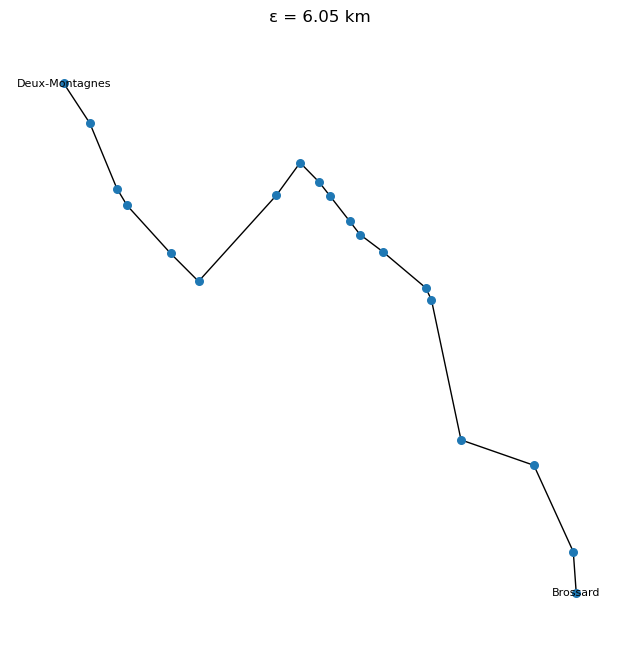

In [122]:
animar_red(G_rem)

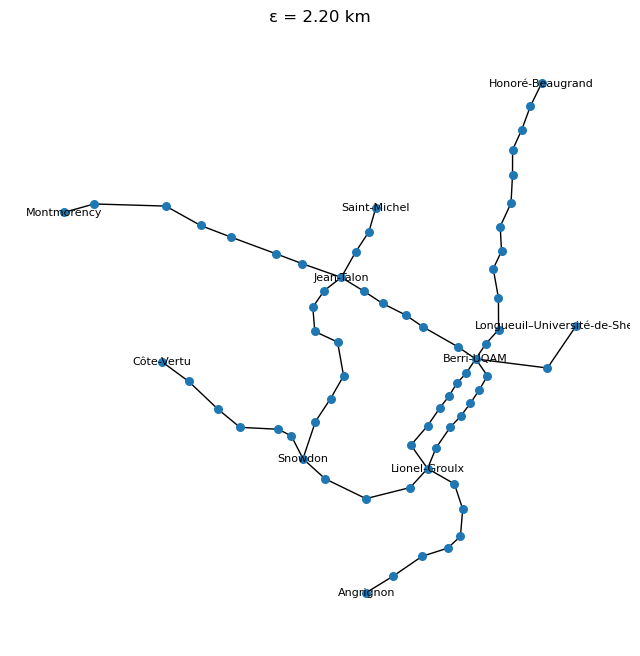

In [123]:
animar_red(G_metro)

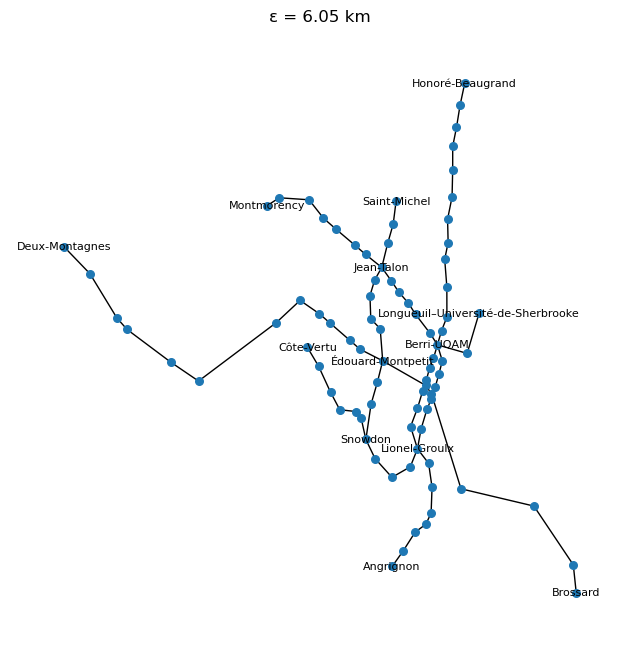

In [124]:
animar_red(G_all,"red_montreal")

Vemos ahora los diagramas de persistencia de cada subred y del sistema completo.
<br>*ripser* es usado para calcular la homología persistente de la red ya que usamos una filtración métrica (y ripser está optimizada para esto).

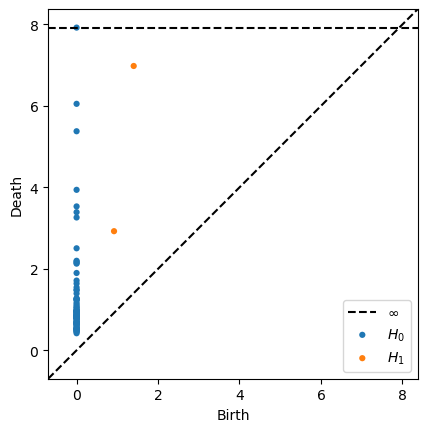

In [125]:
from ripser import ripser
from persim import plot_diagrams

dgms = ripser(D, distance_matrix=True, maxdim=1)["dgms"]
plot_diagrams(dgms, show=True)


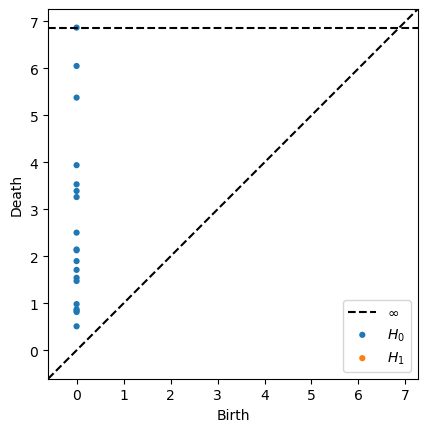

In [126]:
dgms_rem = ripser(D_rem, distance_matrix=True, maxdim=1)["dgms"]
plot_diagrams(dgms_rem, show=True)

## Significado de cada barra (punto (x,y) en el diagrama) 
* Para $H_0:$ existe una estación aislada en $y$ kilómetros del resto de la red
* Para $H_1:$ Existen estaciones separadas $y$ kilómetros, para las cuales hay caminos alternativos (que forman un ciclo) que pasan por estaciones separadas no más de $x$ kilómetros.

**Nota:** las distancias respectivas son tomadas sobre la red, NO es la distancia euclideana/geodésica entre los puntos.

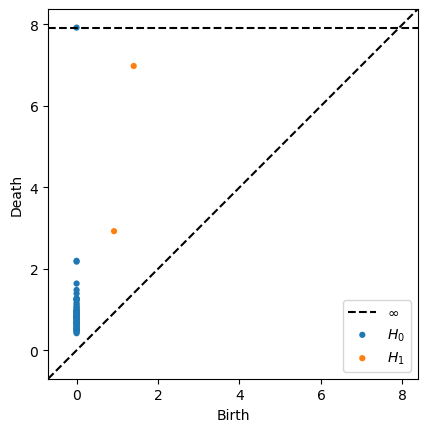

In [127]:
dgms_metro = ripser(D_metro, distance_matrix=True, maxdim=1)["dgms"]
plot_diagrams(dgms_metro, show=True)

### Lo que les debía:
**Observación importante:** La filtración que estamos usando, no es realmente solo del grafo, sino de un complejo de cliques parametrizado por la distancia (es decir, si hay un camino de $t$ km entre dos estaciones $u,v$, para la filtración, aumentamos la arista $u,v$ al grafo, y cada vez que se forme un triángulo, lo rellenamos...   


In [128]:
from itertools import combinations

def rips_filtration_clique_graph(G, verbose = True):
    D = distance_matrix(G)
    max_eps=D.max()
    nodes = list(G.nodes)
    if verbose:
        print (f"{len(nodes) } nodos en el grafo")

    pos = {node: G.nodes[node]["pos"] for node in G.nodes}
    if verbose:
        print (f"{len(pos) } nodos georeferenciados")
    idx_to_node = {i: node for i, node in enumerate(nodes)}
    node_to_idx = {node: i for i, node in enumerate(nodes)}
        
    hubs = set([node for node in G.nodes if G.degree(node)>2])
    if verbose:
        print (f"hubs: { hubs}")

    simplices = []
    n= len (nodes)
    # Vertices at value 0
    vertex_vals = { (node,): 0.0 for node in G.nodes }
    for s,val in vertex_vals.items():
        if verbose:
            print (f"Añaniendo nodo: {s } a la filtración \r")
        
        simplices.append((s, val))
    if verbose:
        print (f"{len(nodes) } vértices añadidos a la filtración")
    
    

    # Edges appear at their corresponding distance (on the graph)
    edges = []
    edge_vals = {}
    max_dist = D.max()
    if verbose:
        print (f"distancia máxima entre estaciones: {max_dist}")
        

    

    for i in range(n):
        for j in range(i+1, n):
            edges.append((idx_to_node[i], idx_to_node[j]))
            edge_vals[idx_to_node[i], idx_to_node[j]] = D[i, j]
    for s,val in edge_vals.items():
        if verbose:
            print (f"Añaniendo arista: {s } a la filtración \r")
        
        simplices.append((s, val))
    if verbose:
        print (f"{len(edges) } aristas añadidos a la filtración")
            

    triangles = []
    triangle_vals = {}

    ## Para graficar, solo usaremos los hubs


    for i,j, k in combinations(range(n), 3):
            val = max(D[i, j], D[i, k], D[j, k])
            triangles.append((idx_to_node[i], idx_to_node[j], idx_to_node[k]))
            triangle_vals[(idx_to_node[i], idx_to_node[j], idx_to_node[k])] = val
    
    for s,val in triangle_vals.items():
       #if verbose:
       #   print (f"Añaniendo triángulo: {s } a la filtración \r")
        
        simplices.append((s, val))
    if verbose:
        print (f"{len(triangles) } triángulos añadidos a la filtración")

    simplices.sort(key=lambda x: x[1])

    return simplices, pos,max_eps
    

In [129]:
simplices, pos,max_eps = rips_filtration_clique_graph(G_all, verbose = False)
print (simplices[-1])

distancia entre McGill_Rem y McGill_Metro (16, 75) actualizada: 13.639853779844849 
distancia entre Bonaventure y Gare Centrale (37, 76) actualizada: 13.331744397689427
((7041520766, 8661983924, 8665496409), np.float64(43.85127942659646))


In [130]:
from matplotlib.patches import Polygon
def animate_rips(G):
    simplices, pos,max_eps = rips_filtration_clique_graph(G, verbose=False)

    # frame values = sorted unique edge weights
    eps_values = np.arange(max_eps,step = max_eps/5)

    fig, ax = plt.subplots(figsize=(6, 6))

    # Precompute limits
    xs = [p[0] for p in pos.values()]
    ys = [p[1] for p in pos.values()]
    xmin, xmax = min(xs) - 0.01, max(xs) + 0.01
    ymin, ymax = min(ys) - 0.01, max(ys) + 0.01

    def update(frame):
        eps = eps_values[frame]
        ax.clear()

        # restore axis state
        ax.set_aspect("equal")
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
        ax.set_xticks([])
        ax.set_yticks([])

        active_vertices = [
            s[0] for s, v in simplices
            if len(s) == 1 and v <= eps
        ]

        active_edges = [
            s for s, v in simplices
            if len(s) == 2 and v <= eps
        ]

        active_tris = [
            s for s, v in simplices
            if len(s) == 3 and v <= eps
        ]

        # Draw triangles FIRST (background)
        for tri in active_tris:
            poly = Polygon(
                [pos[v] for v in tri],
                closed=True,
                facecolor="orange",
                alpha=0.3,
                edgecolor=None
            )
            ax.add_patch(poly)

        # Draw edges
        nx.draw_networkx_edges(
            G, pos,
            edgelist=active_edges,
            ax=ax,
            width=1.5,
            edge_color="black"
        )

        # Draw nodes
        nx.draw_networkx_nodes(
            G, pos,
            nodelist=active_vertices,
            node_size=5,
            node_color="brown",
            ax=ax
        )

        ax.set_title(f"Rips filtration  ε = {eps:.3f}")

        return []

    ani = FuncAnimation(
        fig,
        update,
        frames=len(eps_values),
        interval=600,
        blit=False
    )

    return ani


distancia entre McGill_Rem y McGill_Metro (16, 75) actualizada: 13.639853779844849 
distancia entre Bonaventure y Gare Centrale (37, 76) actualizada: 13.331744397689427


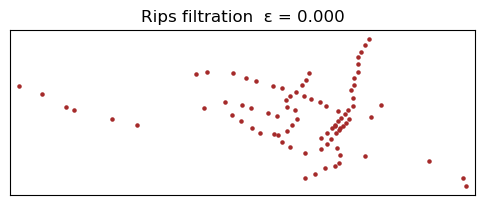

In [131]:
animation_rips = animate_rips(G_all)


In [132]:
file_name = "montreal_rips"
animation_rips.save(
        f"{file_name}.gif",
        writer="pillow",
        fps=4,
        )

[Rips_Montreal_transit](/files/montreal_rips.gif)
[Rips_Montreal_transit(detallado)](/files/montreal_rips1.gif)

## Al fin el análisis
Para comparar la homología persistente de cada subred, debemos hallar una distancia entre sus diagramas de persistencia. 
**Observaciones** Tanto por estabilidad, como por facilidad de cálculo, es preferible usar vectorizaciones de estos diagramas. 
P.ej, imágenes de persistencia o paisajes de persistencia. Éstos además pueden ser usados como características dentro de una línea de ensamblaje (pipeline) de Apendizaje de máquina.


In [133]:
import numpy as np

def global_diagram_bound(dgms_list, margin=0.15):
    max_val = 0
    for dgms in dgms_list:
        for dgm in dgms:
            finite = dgm[np.isfinite(dgm[:, 1])]
            if len(finite) > 0:
                max_val = max(max_val, finite[:, 1].max())
    return (1 + margin) * max_val


In [134]:
import matplotlib.pyplot as plt
from persim import plot_diagrams

def plot_diagrams_comparison(dgms_list, titles,superlevel=False):
    bound = global_diagram_bound(dgms_list)

    fig, axes = plt.subplots(1, len(dgms_list), figsize=(15, 4))

    for ax, dgms, title in zip(axes, dgms_list, titles):
        if superlevel:
            plot_diagrams(
            dgms,
            xy_range=[-bound, 1, -bound, 1],
            show=False
            )
        else:           
            plot_diagrams(
                dgms,
                ax=ax,
                lifetime=False,
                diagonal=True,
                xy_range=[0, bound, 0, bound],
                show=False
            )
        ax.set_title(title)

    plt.tight_layout()
    plt.show()


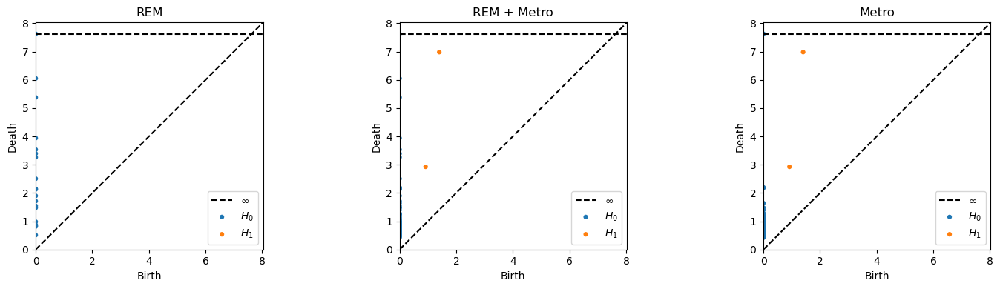

In [135]:
dgms_list  = [dgms_rem, dgms, dgms_metro]
labels =   ["REM", "REM + Metro", "Metro"]
plot_diagrams_comparison(dgms_list, labels)


# Se ven diferentes, 
pero ¿qué tan diferentes son? : Usamos distancia de Wasserstein (emparejamiento perfecto)

In [136]:
from persim import wasserstein

In [137]:
def wasserstein_table(dgms_list, labels, homology_dim=1):
    n = len(dgms_list)
    data = np.zeros((n, n))

    for i in range(n):
        for j in range(n):
            data[i, j] = wasserstein(
                dgms_list[i][homology_dim],
                dgms_list[j][homology_dim],
                matching=False
            )

    return pd.DataFrame(data, index=labels, columns=labels)


In [138]:
print(f"Distancias entre diagramas (H_0):")
display(wasserstein_table(dgms_list, labels, homology_dim=0))
print(f"Distancias entre diagramas (H_1):")
display(wasserstein_table(dgms_list, labels, homology_dim=1))


Distancias entre diagramas (H_0):


C:\Users\David\anaconda3\Lib\site-packages\persim\wasserstein.py:51: UserWarning: dgm1 has points with non-finite death times;ignoring those points
  warnings.warn(
C:\Users\David\anaconda3\Lib\site-packages\persim\wasserstein.py:61: UserWarning: dgm2 has points with non-finite death times;ignoring those points
  warnings.warn(
C:\Users\David\anaconda3\Lib\site-packages\persim\wasserstein.py:51: UserWarning: dgm1 has points with non-finite death times;ignoring those points
  warnings.warn(
C:\Users\David\anaconda3\Lib\site-packages\persim\wasserstein.py:61: UserWarning: dgm2 has points with non-finite death times;ignoring those points
  warnings.warn(
C:\Users\David\anaconda3\Lib\site-packages\persim\wasserstein.py:51: UserWarning: dgm1 has points with non-finite death times;ignoring those points
  warnings.warn(
C:\Users\David\anaconda3\Lib\site-packages\persim\wasserstein.py:61: UserWarning: dgm2 has points with non-finite death times;ignoring those points
  warnings.warn(
C:\Users\D

,REM,REM + Metro,Metro
REM,0.000000,42.036367,46.503027
REM + Metro,42.036367,0.000000,30.392291
Metro,46.503027,30.392291,0.000000


Distancias entre diagramas (H_1):


,REM,REM + Metro,Metro
REM,0.00000,5.36214,5.36214
REM + Metro,5.36214,0.00000,0.00000
Metro,5.36214,0.00000,0.00000


En realidad, sabemos que nuestros diagramas son estables a partir de un punto dado (relacionado a la distancia máxima entre las estaciones), por eso reemplazaremos las barras infinitas por barras hasta ese valor. Esto también servirá para comparar de mejor manera las vectorizaciones obtenidas.

In [139]:
INF_CAP = global_diagram_bound(dgms_list)
print (INF_CAP)

8.027532482147215


In [140]:
def clip_diagram(dgm, cap):
    dgm = dgm.copy()
    inf_mask = ~np.isfinite(dgm[:, 1])
    dgm[inf_mask, 1] = cap
    return dgm


In [141]:
dgms_clipped = [
    [clip_diagram(dgm, INF_CAP) for dgm in dgms]
    for dgms in dgms_list
]


Todas las comparaciones se harán con los diagramas recortados (fijando una cota para reemplazar el infinito)

In [142]:
print(f"Distancias entre diagramas (H_0):")
display(wasserstein_table(dgms_clipped, labels, homology_dim=0))
print(f"Distancias entre diagramas (H_1):")
display(wasserstein_table(dgms_clipped, labels, homology_dim=1))


Distancias entre diagramas (H_0):


,REM,REM + Metro,Metro
REM,0.000000,42.036367,46.503027
REM + Metro,42.036367,0.000000,30.392291
Metro,46.503027,30.392291,0.000000


Distancias entre diagramas (H_1):


,REM,REM + Metro,Metro
REM,0.00000,5.36214,5.36214
REM + Metro,5.36214,0.00000,0.00000
Metro,5.36214,0.00000,0.00000


# Vectorizaciones
Se presentarán las tres vectorizaciones más comunes para cada diagrama:
* Paisaje de persistencia
* Silueta de persistencia
* Imagen de persistencia

In [143]:
def persistence_landscape(dgm, xs, k=1):
    tents = []
    for b, d in dgm:
        m = 0.5 * (b + d)
        h = 0.5 * (d - b)
        tents.append(np.maximum(0, h - np.abs(xs - m)))

    tents = np.array(tents)
    tents.sort(axis=0)
    return tents[-k:]


### Paisaje de persistencia
Crea cadenas de montañas, obtenidas al girar la imagen de persistencia y dibujar una carpa/montaña por cada barra.<br>
**xs:** rango y discretización en x.<br>
**k:** dimensión.

In [144]:
xs = np.linspace(0, INF_CAP, 200)
L_ejm = persistence_landscape(dgms_clipped[1][1], xs, k=3)
L_ejm

array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 9.58412856e-03,
        4.99234878e-02, 9.02628470e-02, 1.30602206e-01, 1.70941565e-01,
        2.11280925e-01, 2.51620284e-01, 2.91959643e-01, 3.32299002e-01,
        3.72638361e-01, 4.12977721e-01, 4.53317080e-01, 4.93656439e-01,
        5.33995798e-01, 5.74335157e-01, 6.14674517e-01, 6.55013876e-01,
        6.95353235e-01, 7.35692594e-01, 7.46112603e-01, 7.057732

### Silueta de persistencia
Suma ponderada de los paisajes (por defecto, ponderada por "tiempo de vida" de la barra.

In [145]:
def persistence_silhouette(dgm, xs, weight=None):
    if weight is None:
        weight = lambda b, d: d - b

    S = np.zeros_like(xs)
    W = 0.0

    for b, d in dgm:
        w = weight(b, d)
        m = 0.5 * (b + d)
        h = 0.5 * (d - b)
        tent = np.maximum(0, h - np.abs(xs - m))
        S += w * tent
        W += w

    return S / W if W > 0 else S


### Imagen de persistencia
Mapa de calor (suavizado) del diagrama de persistencia.

In [146]:
def persistence_image(dgm, x_bins, y_bins, sigma):
    img = np.zeros((len(x_bins), len(y_bins)))

    for b, d in dgm:
        for i, x in enumerate(x_bins):
            for j, y in enumerate(y_bins):
                img[i, j] += np.exp(
                    -((x - b)**2 + (y - (d - b))**2) / (2 * sigma**2)
                )

    return img


In [147]:
def plot_vectorizations_grid(
    dgms_list,
    labels,
    dim,
    inf_cap,
    n_landscape_layers=3,
    n_landscape_pts=300,
    img_resolution=25,
    img_sigma=0.05
):
    """
    3 columns: filtrations
    3 rows: landscapes / silhouettes / images
    """

    xs = np.linspace(0, inf_cap, n_landscape_pts)
    x_bins = np.linspace(0, inf_cap, img_resolution)
    y_bins = np.linspace(0, inf_cap, img_resolution)

    fig, axes = plt.subplots(3, 3, figsize=(12, 9))

    for col, (dgms, label) in enumerate(zip(dgms_list, labels)):
        dgm = dgms[dim]

        # ---- Landscapes (row 0)
        L = persistence_landscape(dgm, xs, k=n_landscape_layers)
        for k in range(L.shape[0]):
            axes[0, col].plot(xs, L[k])
        axes[0, col].set_title(label)
        axes[0, col].set_xlim(0, inf_cap)

        # ---- Silhouette (row 1)
        S = persistence_silhouette(dgm, xs)
        axes[1, col].plot(xs, S)
        axes[1, col].set_xlim(0, inf_cap)

        # ---- Persistence image (row 2)
        img = persistence_image(dgm, x_bins, y_bins, img_sigma * inf_cap)
        axes[2, col].imshow(
            img,
            origin="lower",
            extent=[0, inf_cap, 0, inf_cap],
            aspect="auto"
        )

    # Row labels
    axes[0, 0].set_ylabel("Landscape")
    axes[1, 0].set_ylabel("Silhouette")
    axes[2, 0].set_ylabel("Persistence Image")

    for ax in axes.flatten():
        ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

    fig.suptitle(f"Topological Vectorizations – H_{dim}", fontsize=14)
    plt.tight_layout()
    plt.show()


Dibujar las vectorizaciones para $H_0$

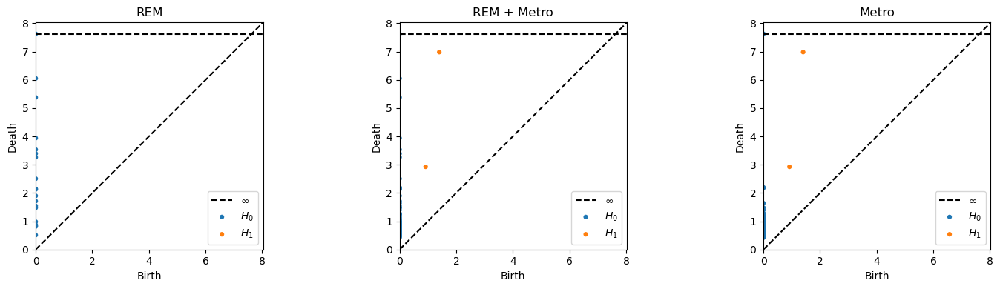

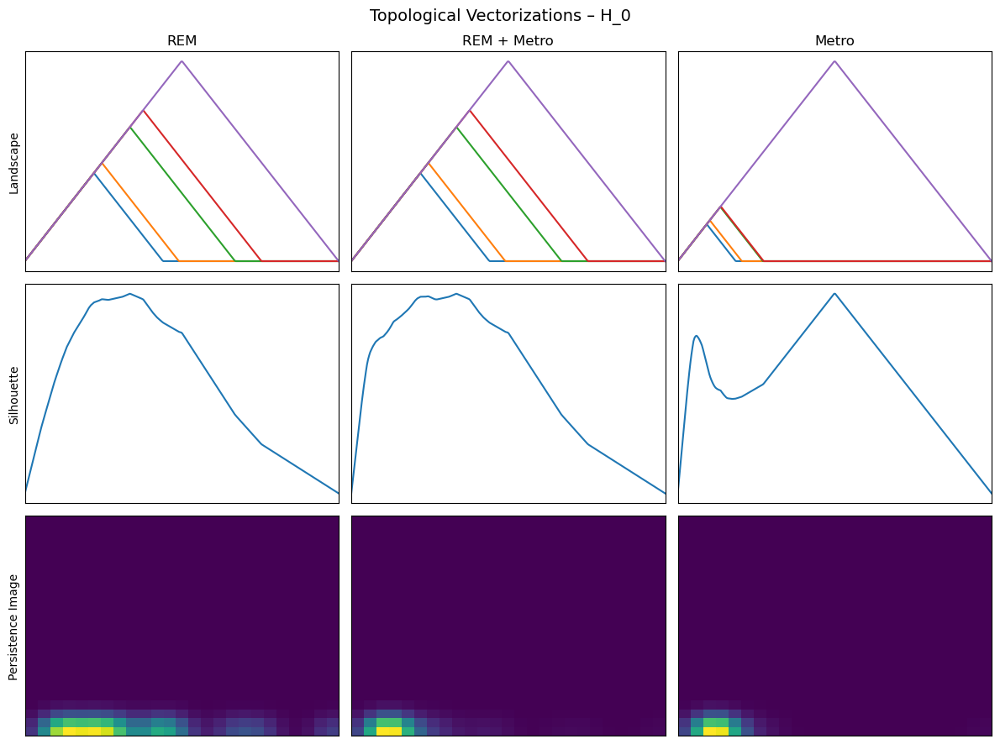

In [148]:
plot_diagrams_comparison(dgms_list, labels)

plot_vectorizations_grid(
    dgms_clipped,
    labels,
    n_landscape_layers=5,
    dim=0,
    inf_cap=INF_CAP
)



Dibujar las vectorizaciones para $H_1$

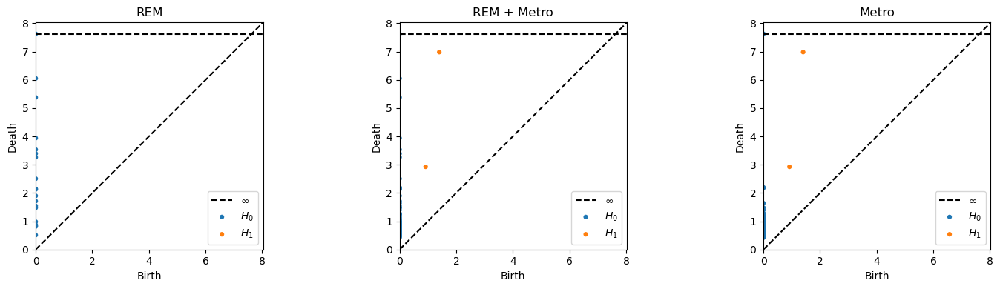

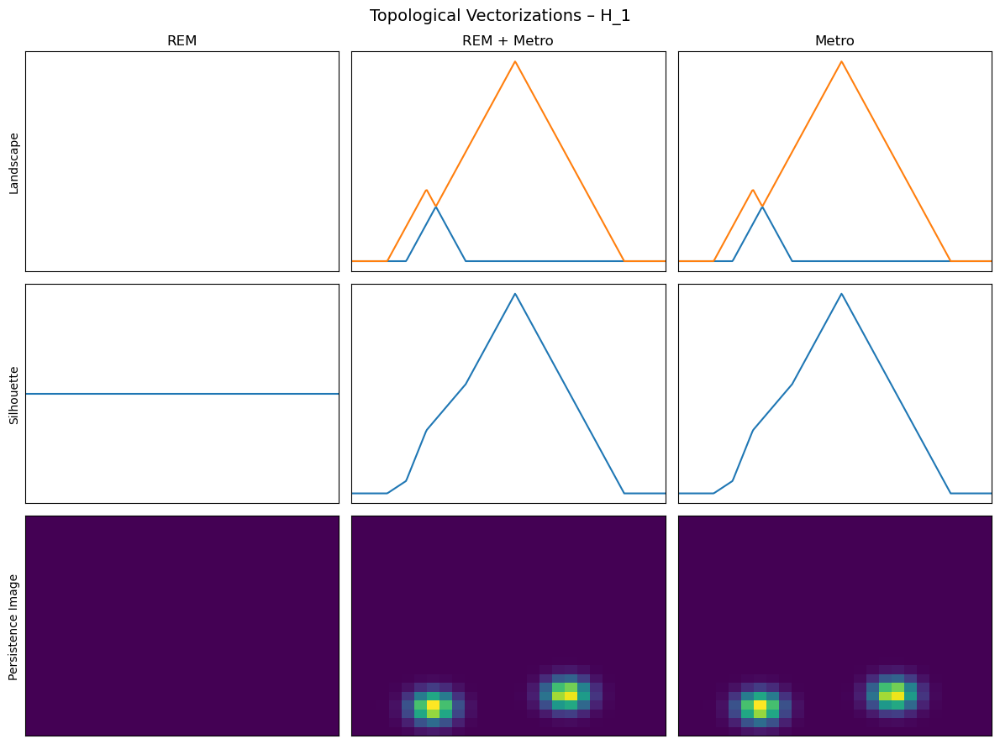

In [149]:
plot_diagrams_comparison(dgms_list, labels)

plot_vectorizations_grid(
    dgms_clipped,
    labels,
    dim=1,
    inf_cap=INF_CAP
)



## Recordar:
* Todo grafo (conexo) con pesos no negativos induce un espacio métrico.
* Todo espacio métrico discreto admite una filtración de RIPS
* Existen OTRAS filtraciones que "detectan" otra parte de la estructura del espacio estudiado. 

## Otras filtraciones interesantes en grafos
Recordemos que:
* En una filtración un símplice no debe aparecer antes (pero tal vez sí, junto) a sus partes.
* Si solamente usamos el grafo original, técnicas más sencillas son equivalentes a usar TDA. Por tanto usamos la filtración en el complejo de cliques del grafo extendido "a la Rips".

Una Forma "natural" de crear una filtración en (complejos de clique de) grafos es usar una función definida sobre sus vértices y extenderla a símplices de mayor dimensión (de forma que se respete la regla). Este tipo de filtración es llamada "function-based lower-star"  (de baja estrella basada en una función¿? Filtración por extensión de una función).<br>
Una función fácil de calcular y que tiene relevancia en los nodos de un grafo es su grado. Esto permite estudiar la conectividad del grafo como objeto puramente combinatorio/topológico (sin distancias). 



Ésta vez usaremos Gudhi, ya que funciona bien para filtraciones genéricas

In [150]:
import gudhi as gd



In [151]:
def crear_filtracion_grado (G):
    ## Problema técnico, Gudhi usa long int from C, la id de la estación es un número muy grande para convertirlo... 
    ## Recordar temas computacionales también
    node_to_idx = {node: i for i, node in enumerate(G.nodes())}
    idx_to_node = {i: node for node, i in node_to_idx.items()}
    G_idx = nx.relabel_nodes(G, node_to_idx, copy=True)
    pos = {node: G.nodes[node]["pos"] for node in G.nodes}

    pos_idx = {node_to_idx[n]: p for n, p in pos.items()}
    for n, data in G.nodes(data=True):
        G_idx.nodes[node_to_idx[n]].update(data)

    
    st = gd.SimplexTree()
    # Nodos insertados según el grado
    f = {v: -G_idx.degree(v) for v in G_idx.nodes()}

    # aristas cuando ambos nodos aparezcan
    for u, v in G_idx.edges():
        f = max(-G_idx.degree(u), -G_idx.degree(v))
        st.insert([u, v], filtration=f)

    # triángulos cuando todos sus lados aparezcan
    st.expansion(2)  # triangles
    st.make_filtration_non_decreasing()
    return st

Calcular sus diagramas de persistencia:

In [152]:
dgm_grado_rem = crear_filtracion_grado(G_rem).persistence()
dgm_grado_metro = crear_filtracion_grado(G_metro).persistence()
dgm_grado_all = crear_filtracion_grado(G_all).persistence()

In [153]:
print (dgm_grado_rem)

[(0, (-2.0, inf))]


Ahora, podemos repetir lo que ya hemos hecho antes...

Gudhi y Ripser usan diferentes estructuras para guardar un código de barras.<br>
Se deberá hacer una transformación previa para poder usar nuestras visualizaciones anteriores.


In [154]:
print (dgm_grado_rem) # Formato Gudhi
print(dgms_rem) # Formato Ripser (scikit-TDA)

[(0, (-2.0, inf))]
[array([[0.        , 0.51080924],
       [0.        , 0.81517696],
       [0.        , 0.84053308],
       [0.        , 0.87185591],
       [0.        , 0.98289865],
       [0.        , 1.47510195],
       [0.        , 1.54345381],
       [0.        , 1.71159649],
       [0.        , 1.89819729],
       [0.        , 2.12782383],
       [0.        , 2.14624047],
       [0.        , 2.50426841],
       [0.        , 3.26094985],
       [0.        , 3.39066982],
       [0.        , 3.53232503],
       [0.        , 3.93996906],
       [0.        , 5.37803078],
       [0.        , 6.05128956],
       [0.        ,        inf]]), array([], shape=(0, 2), dtype=float64)]


In [155]:
def gudhi_to_ripser(diag, maxdim):
    dgms = [[] for _ in range(maxdim + 1)]
    for dim, (b, d) in diag:
        if dim <= maxdim:
            dgms[dim].append([b, d])
    return [np.array(dgm) if len(dgm) else np.empty((0,2)) for dgm in dgms]


In [156]:

dgm_grado_list = [gudhi_to_ripser(diag, maxdim = 1) for diag in [dgm_grado_rem, dgm_grado_all,  dgm_grado_metro]]
dgm_grado_list_clipped = [
    [clip_diagram(dgm, 0) for dgm in dgms]
    for dgms in dgm_grado_list
]

print(dgm_grado_list_clipped)



[[array([[-2.,  0.]]), array([], shape=(0, 2), dtype=float64)], [array([[-2.,  0.]]), array([], shape=(0, 2), dtype=float64)], [array([[-2.,  0.]]), array([], shape=(0, 2), dtype=float64)]]


### Intento de gráfico...
Busquen el problema

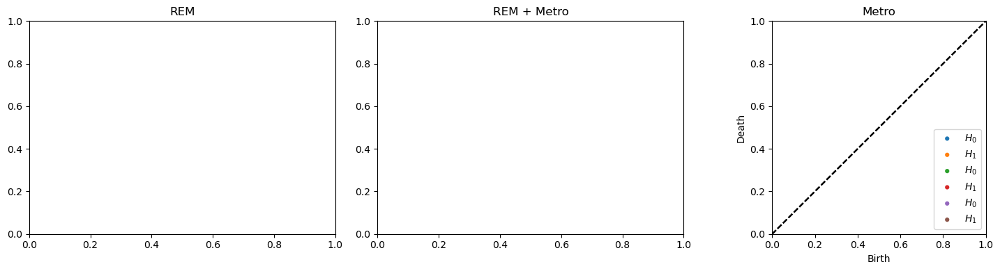

In [157]:
plot_diagrams_comparison(dgm_grado_list_clipped, labels, superlevel= True)


In [158]:
import numpy as np

def add_virtual_diagonal_point(dgm, value=4.0):
    dgm = np.asarray(dgm)
    if dgm.size == 0:
        return np.array([[value, value]])
    return np.vstack([dgm, [value, value],[-value, -value]])


In [159]:
def sanitize_diagrams(dgms, diag_value=4.0):
    return [
        add_virtual_diagonal_point(dgm, diag_value)
        for dgm in dgms
    ]

dgms_grado_listos = [
    sanitize_diagrams(dgms) for dgms in dgm_grado_list_clipped
]


In [160]:
dgms_grado_listos

[[array([[-2.,  0.],
         [ 4.,  4.],
         [-4., -4.]]),
  array([[4., 4.]])],
 [array([[-2.,  0.],
         [ 4.,  4.],
         [-4., -4.]]),
  array([[4., 4.]])],
 [array([[-2.,  0.],
         [ 4.,  4.],
         [-4., -4.]]),
  array([[4., 4.]])]]

El grafo para una de las redes...

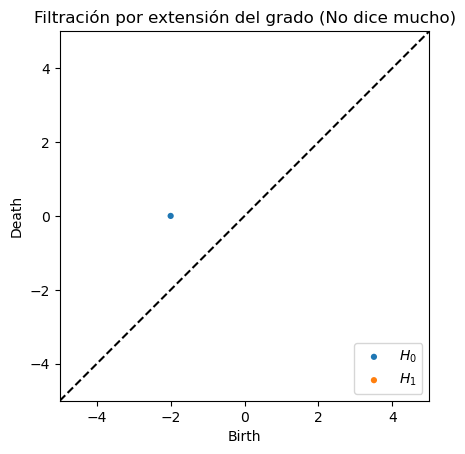

In [161]:
from persim import plot_diagrams
import matplotlib.pyplot as plt

T = 5  # or max degree / max filtration value

plot_diagrams(
    dgm_grado_list_clipped[0],
    xy_range=[-T, T, -T, T],
    show=False
)

plt.title("Filtración por extensión del grado (No dice mucho)")
plt.show()


Lastimosamente, en el caso de una (pequeña) red de transporte es que muchos nodos tendrán el mismo grado, por lo tanto muchas barras "morirán al instante". 

## Ejercicio:
Cambiar la filtración de grado definida en 
<br>
def crear_filtracion_grado (G):...<br>
Se puede usar, por ejemplo el "grado ponderado" (suma de los pesos de las aristas incidentes)<br>
O en realidad cualquier función como "número de caracteres en el nombre de la estación" (Obviamente, más numerología que TDA)<br>
Otra opción interesante es la distancia a las estaciones de transferencia (hubs) o a los terminales...